# Rec Centre Bookings: Inspect, Clean, Transform
SDEV2501 · Days 10-11 · **Finished notebook**

The City's recreation department exported every booking from **September 2026** and handed it to us. We want two things out of it: which facility makes the most money, and when people actually show up.

We can't answer either one yet. The same activity is spelled several different ways ("Lane Swim", "lane swim", "LANE SWIM", "Swim"), some numbers are stored as text, and some rows are copies of others. So first we work out *how* messy the data is, then we clean it, then we reshape it so it can answer a question with numbers we trust.

This is the finished version of the student notebook: every code cell is completed and run, and every question is answered. Use it to check your own work after you've had a go.

**Files (same folder as this notebook):** `bookings_sept_messy.csv`, `facilities.csv`

> Mock data. The bookings and members are made up; the neighbourhoods are real Edmonton ones.

## 0. Setup
Run this cell to import the libraries.

In [1]:
# pandas: tables. numpy: we only need np.nan (pandas' "missing" value).
# matplotlib.pyplot: charts (pandas' .plot() uses it behind the scenes).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

---
# Part 1: Inspect & Clean (Day 10)
One rule for today: **look before you touch.** It's tempting to fix the first problem you spot. Don't. Find everything first and write it down, *then* start changing things. If you fix problems as you find them, an early fix can hide a later problem: for example, converting `Hours ` to numbers with `errors="coerce"` before you've looked would quietly turn the text `"unknown"` into a blank, and you'd never know it was there.

## 1. Load
Load `bookings_sept_messy.csv` into a DataFrame called `df` and show the first 10 rows.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(...)` | Reads a CSV file into a DataFrame. The file has to be in the same folder as the notebook. |
| `head(...)` | Shows the first rows (5 if you leave the brackets empty). It doesn't change anything. |

In [2]:
# Read the CSV into a DataFrame (a table with named columns).
df = pd.read_csv("bookings_sept_messy.csv")

# Peek at the first 10 rows.
df.head(10)

,Booking ID,Member #,Facility ID,Activity,Booking Date,Hours,Hourly Rate,Status
0,5036,M1035,F06,Lane Swim,"Sep 26, 2026",2,$8.00,Completed
1,5103,M1049,F01,Lane Swim,2026-09-19,1,$8.00,Completed
2,5063,M1028,F04,Court Rental,2026-09-08,1,45.00,Completed
3,5122,M1051,F02,Gym Drop-in,2026-09-18,1,$10.00,Completed
4,5113,M1018,F06,LANE SWIM,2026-09-05,1.5,8.00,Completed
5,5054,M1005,F03,Public Skate,2026-09-22,1,6.00,Completed
6,5050,M1006,F04,court rental,09/04/2026,2,45.00,Completed
7,5069,M1045,F05,Gym Drop-in,2026-09-16,1.5,10.00,Completed
8,5006,M1049,F02,Gym Drop In,2026-09-22,3,10.00,Completed
9,5073,M1034,F03,Public Skate,2026-09-03,1,6.00,Completed


Find out how many rows and columns there are, and what the columns are called.

| You'll need | What it's for |
|---|---|
| `.shape` | The number of rows and columns. It's an attribute, so no brackets. |
| `list(df.columns)` | The column names as a list. Each name is printed in quotes, which makes hidden spaces visible. |

In [3]:
# (rows, columns)
print(df.shape)

# list() prints every name in quotes, so a trailing space shows up.
list(df.columns)

(146, 8)


['Booking ID',
 'Member #',
 'Facility ID',
 'Activity',
 'Booking Date',
 'Hours ',
 'Hourly Rate',
 'Status']

Explain what you notice about the column names.

*Answer:*

There are 146 rows and 8 columns. The names are inconsistent: they mix capitals and spaces (`Booking ID`, `Hourly Rate`), one has a `#` in it (`Member #`), and `'Hours '` has a trailing space. That last one matters straight away: `df["Hours"]` raises a `KeyError`, so until we rename the columns in 3.1 we have to type `df["Hours "]` with the space.

## 2. Inspect
Nothing in this section changes `df`. The goal is to find and record problems, not fix them. Every time you find a problem, add it to the **findings table** at the end of section 2.

### 2.1 Missing values
Count the missing values in each column.

| You'll need | What it's for |
|---|---|
| `isna()` | Returns a table the same size as `df`, with `True` wherever a value is missing (`NaN`). |
| `sum()` | Adds up each column. `True` counts as 1, so the result is the number of missing values per column. |

In [4]:
# isna() marks every missing value True; sum() counts the Trues in each column.
df.isna().sum()

Booking ID      0
Member #        0
Facility ID     0
Activity        0
Booking Date    0
Hours           4
Hourly Rate     2
Status          0
dtype: int64

### 2.2 Duplicates
Find out how many rows are exact copies of an earlier row. Show every copy, sorted by booking ID so the pairs sit together.

| You'll need | What it's for |
|---|---|
| `duplicated()` | `True` for each row that repeats an earlier row in every column. The first copy is `False`, so `sum()` counts the extras. |
| `duplicated(keep=...)` | `keep=False` marks *all* the copies as `True`, so you can see both halves of each pair. |
| `df[...]` with a True/False Series | Keeps only the rows where the Series is `True`. This is called filtering. |
| `sort_values(...)` | Sorts the rows by the column you name. |

In [5]:
# How many rows repeat an earlier row in every column?
print("Exact duplicate rows:", df.duplicated().sum())

# keep=False marks both copies, so each pair shows up together after sorting.
df[df.duplicated(keep=False)].sort_values("Booking ID")

Exact duplicate rows: 5


,Booking ID,Member #,Facility ID,Activity,Booking Date,Hours,Hourly Rate,Status
8,5006,M1049,F02,Gym Drop In,2026-09-22,3,10.00,Completed
59,5006,M1049,F02,Gym Drop In,2026-09-22,3,10.00,Completed
96,5031,M1014,f03,Public Skate,2026-09-21,2,6.00,Cancelled
79,5031,M1014,f03,Public Skate,2026-09-21,2,6.00,Cancelled
56,5046,M1003,F04,Court rental,2026-09-04,2,45.00,Completed
130,5046,M1003,F04,Court rental,2026-09-04,2,45.00,Completed
105,5090,M1016,F01,Lane Swim,2026-09-08,1,$8.00,completed
69,5090,M1016,F01,Lane Swim,2026-09-08,1,$8.00,completed
103,5110,M1055,F06,Lane Swim,"Sep 20, 2026",1,8.00,Complete
51,5110,M1055,F06,Lane Swim,"Sep 20, 2026",1,8.00,Complete


Every booking should have its own ID. Check whether any `Booking ID` appears more than once.

| You'll need | What it's for |
|---|---|
| `df["..."]` | Picks out one column as a Series. |
| `duplicated()` on one column | Compares only that column, so it also catches rows that share an ID but differ somewhere else. |

In [6]:
# Checking only the ID column catches repeats that differ in other columns.
print("Repeated booking IDs:", df["Booking ID"].duplicated().sum())
df[df["Booking ID"].duplicated(keep=False)].sort_values("Booking ID")

Repeated booking IDs: 6


,Booking ID,Member #,Facility ID,Activity,Booking Date,Hours,Hourly Rate,Status
8,5006,M1049,F02,Gym Drop In,2026-09-22,3,10.00,Completed
59,5006,M1049,F02,Gym Drop In,2026-09-22,3,10.00,Completed
96,5031,M1014,f03,Public Skate,2026-09-21,2,6.00,Cancelled
79,5031,M1014,f03,Public Skate,2026-09-21,2,6.00,Cancelled
56,5046,M1003,F04,Court rental,2026-09-04,2,45.00,Completed
130,5046,M1003,F04,Court rental,2026-09-04,2,45.00,Completed
111,5071,M1042,F01,lane swim,2026-09-16,20,8.00,Canceled
135,5071,M1042,F01,lane swim,2026-09-16,1.5,8.00,Canceled
69,5090,M1016,F01,Lane Swim,2026-09-08,1,$8.00,completed
105,5090,M1016,F01,Lane Swim,2026-09-08,1,$8.00,completed


Explain why the two checks give different counts, and which copy of the odd one out you'd believe.

*Answer:*

There are 5 exact duplicate rows but 6 repeated IDs. The extra one is booking 5071: same member, same facility, same day, but one copy says 20 hours and the other says 1.5. Because the rows aren't identical, the whole-row check doesn't count it. The 1.5-hour copy is the believable one; a 20-hour lane swim isn't.

### 2.3 Unexpected categories
List every value in `Activity`, `Status` and `Facility ID`, with counts. To you, `Lane Swim` and `lane swim` are the same activity, but pandas treats them as two different values because the text isn't identical.

| You'll need | What it's for |
|---|---|
| `value_counts()` | Counts how many times each distinct value appears in a column, most common first. |

In [7]:
# Each distinct spelling gets its own row.
df["Activity"].value_counts()

Activity
Lane Swim        38
Court Rental     17
Public Skate     17
Gym Drop-in      15
Fitness Class    11
Lane  Swim        7
Gym Drop In       6
Court rental      5
court rental      4
public skate      4
PUBLIC SKATE      4
Swim              3
gym drop-in       3
lane swim         3
LANE SWIM         2
Gym drop-in       2
fitness class     2
FITNESS CLASS     1
Skate             1
Fitness class     1
Name: count, dtype: int64

In [8]:
df["Status"].value_counts()

Status
Completed    97
completed    14
COMPLETE      8
Cancelled     7
No-show       6
Complete      6
Canceled      4
No Show       2
no show       2
Name: count, dtype: int64

In [9]:
df["Facility ID"].value_counts()

Facility ID
F01    27
F04    26
F06    22
F02    21
F03    21
F05    17
f03     5
f02     3
F07     3
f01     1
Name: count, dtype: int64

Explain how many different spellings each column has, and how many real values they stand for.

*Answer:*

`Activity` has 20 different spellings of 5 real activities (Lane Swim, Public Skate, Gym Drop-In, Fitness Class, Court Rental). Some differ only in case or spacing (`LANE SWIM`, `Lane  Swim`), and three are short forms (`Swim`, `Skate`, `Gym Drop In`). `Status` has 9 spellings of 3 values (completed, cancelled, no-show). `Facility ID` has lowercase versions of some codes (`f01` to `f03`) and a code, `F07`, that we'll check against the facilities list in Part 2.

### 2.4 Impossible values
An **impossible** value can't be true no matter what. A booking can't last zero or negative hours, and September has only 30 days.

`Hours ` is stored as text (more on that in 2.5), so make a temporary numeric copy called `hours_check`, then look at its summary statistics. Then show any rows with zero or negative hours.

| You'll need | What it's for |
|---|---|
| `pd.to_numeric(..., errors=...)` | Converts text to numbers. `errors="coerce"` turns anything that won't convert into `NaN` instead of raising an error. |
| `describe()` | Count, mean, standard deviation, min, quartiles and max. The min and max are where impossible values show up. |
| a comparison such as `... <= 0` | Builds a True/False Series you can use to filter `df`. |

In [10]:
# A separate variable, so df itself stays untouched.
hours_check = pd.to_numeric(df["Hours "], errors="coerce")
hours_check.describe()

count    141.000000
mean       1.836879
std        2.540737
min       -2.000000
25%        1.000000
50%        1.500000
75%        2.000000
max       24.000000
Name: Hours , dtype: float64

In [11]:
# Rows where the hours are zero or negative.
df[hours_check <= 0]

,Booking ID,Member #,Facility ID,Activity,Booking Date,Hours,Hourly Rate,Status
71,5034,M1002,F06,Lane Swim,"Sep 16, 2026",-2,8.00,Cancelled


Explain what the summary tells you, including the `count`.

*Answer:*

The minimum is -2 hours (booking 5034), which is impossible. The maximum is 24 hours, which is possible but worth a look (2.6). The `count` is 141, but there are 142 non-blank values (146 rows minus 4 blanks), so one value didn't convert to a number. That's the lead into 2.5.

### 2.5 Wrong data types
Check the data type of every column.

| You'll need | What it's for |
|---|---|
| `info()` | Lists every column with its dtype (data type) and how many values aren't missing. |

In [12]:
# dtype per column: int64 = whole numbers, float64 = decimals, str = text.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Booking ID    146 non-null    int64
 1   Member #      146 non-null    str  
 2   Facility ID   146 non-null    str  
 3   Activity      146 non-null    str  
 4   Booking Date  146 non-null    str  
 5   Hours         142 non-null    str  
 6   Hourly Rate   144 non-null    str  
 7   Status        146 non-null    str  
dtypes: int64(1), str(7)
memory usage: 9.3 KB


Find the `Hours ` values that are **not blank** but **didn't convert** to a number. Then list the distinct values in `Hourly Rate`.

| You'll need | What it's for |
|---|---|
| `notna()` | The opposite of `isna()`: `True` where there *is* a value. |
| `&` | Combines two True/False Series: both must be `True`. Wrap each condition in brackets. |
| `unique()` | Lists each distinct value once, which makes stray symbols easy to spot. |

In [13]:
# Didn't convert AND wasn't blank = text that isn't a number.
df[hours_check.isna() & df["Hours "].notna()]

,Booking ID,Member #,Facility ID,Activity,Booking Date,Hours,Hourly Rate,Status
100,5041,M1057,F06,Lane Swim,2026-09-09,unknown,8.00,Completed


In [14]:
df["Hourly Rate"].unique()

<StringArray>
[ '$8.00',  '45.00', '$10.00',   '8.00',   '6.00',  '10.00',  '12.00',
      nan, '$45.00', '$12.00',  '$6.00', '450.00']
Length: 12, dtype: str

Explain which columns have the wrong type and why.

*Answer:*

`Hours ` is `str` because one row says `"unknown"` instead of a number. `Hourly Rate` is `str` because some values have a `$` in front and some don't (and one is `450.00`, which 2.6 looks at). `Booking Date` is `str` and written in several formats; we deal with it in Part 2. While a number column is stored as text you can't add, average or sort it properly.

### 2.6 Suspicious distributions
A **suspicious** value is possible, but unusual enough that a person should check it before anyone trusts it. An impossible value is wrong; a suspicious value needs checking.

Plot a histogram of `hours_check`. Then make a numeric copy of the rate called `rate_check` (remove the `$` first) and plot that too.

| You'll need | What it's for |
|---|---|
| `.plot(kind="hist", bins=...)` | Splits the values into ranges (bins) and draws a bar for how many values fall in each one. |
| `plt.title()`, `plt.xlabel()`, `plt.ylabel()` | The chart title and the two axis labels, with units. |
| `.str.replace(..., ..., regex=False)` | Replaces text in every value of a column. `regex=False` treats `$` as a plain character. |
| `plt.show()` | Displays the chart. |

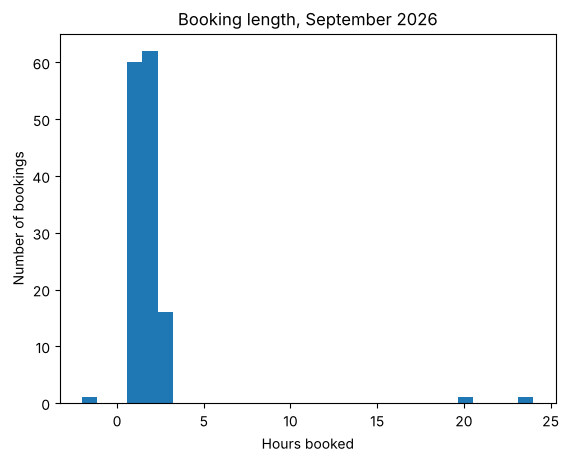

In [15]:
# 30 bins between the smallest and largest value.
hours_check.plot(kind="hist", bins=30)
plt.title("Booking length, September 2026")
plt.xlabel("Hours booked")
plt.ylabel("Number of bookings")
plt.show()

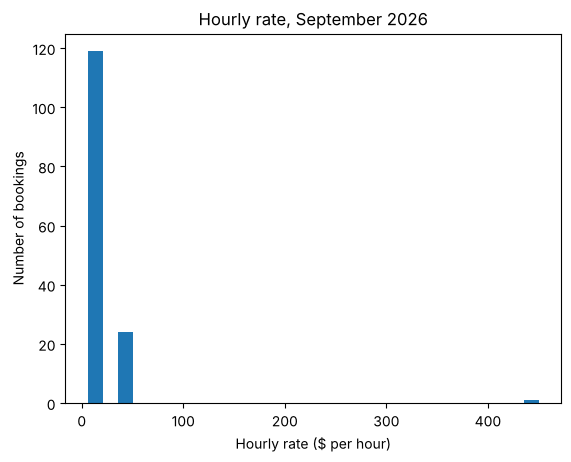

In [16]:
# Remove the $ first, then convert. regex=False: treat "$" as a plain character.
rate_check = pd.to_numeric(df["Hourly Rate"].str.replace("$", "", regex=False), errors="coerce")

rate_check.plot(kind="hist", bins=30)
plt.title("Hourly rate, September 2026")
plt.xlabel("Hourly rate ($ per hour)")
plt.ylabel("Number of bookings")
plt.show()

Explain which values sit far away from everything else.

*Answer:*

In the hours histogram almost every booking is 1 to 3 hours, with two bars far to the right: 20 hours (the duplicate copy of booking 5071) and 24 hours (booking 5089, a court rental). In the rate histogram one bar sits out at $450 while everything else is $45 or less. The standard court rate is $45, so $450 is almost certainly a decimal slip.

### Findings
Fill this in as you go, one row per problem.

| # | Problem | Column(s) | How you found it |
|---|---|---|---|
| 1 | Messy column names (trailing space, `#`, capitals) | all | `list(df.columns)` |
| 2 | Missing values | Hours (4), Hourly Rate (2) | `.isna().sum()` |
| 3 | 5 exact duplicate rows | all | `.duplicated()` |
| 4 | Booking 5071 twice: 20 h and 1.5 h | Booking ID | `.duplicated()` on the ID |
| 5 | Same value, many spellings | Activity (20), Status (9), Facility ID (lowercase) | `.value_counts()` |
| 6 | Negative hours (-2) | Hours | `.describe()` min |
| 7 | Numbers stored as text (`"unknown"`, `$`) | Hours, Hourly Rate | `.info()`, `.unique()` |
| 8 | Dates stored as text, mixed formats | Booking Date | `.head()`, `.info()` |
| 9 | 24 h booking, $450 rate | Hours, Hourly Rate | histogram |

## 3. Clean
Now we change things. Work down the findings table, and for every fix ask one question: **do I know the right answer, or am I guessing?** If you know, fix it. If you'd be guessing, flag it or leave it.

A guess that's presented as a fix ends up in totals and reports as if it were real data, and nobody downstream can tell the difference.

### 3.1 Rename columns
Clean every column name in one go: strip spaces, lowercase, spaces to underscores. Then rename `member_#` to `member_id`.

| You'll need | What it's for |
|---|---|
| `df.columns.str...` | The `.str` accessor runs a string method on every column name at once, e.g. `.str.strip()`, `.str.lower()`, `.str.replace(...)`. |
| `rename(columns={...})` | Renames only the columns you list in the dictionary (`old: new`). |
| assigning back | Neither of these changes `df` by itself; assign the result back to `df.columns` or `df`. |

In [17]:
# Strip spaces from both ends, lowercase, then spaces -> underscores.
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# The dictionary says old name -> new name. Assign the result back.
df = df.rename(columns={"member_#": "member_id"})
list(df.columns)

['booking_id',
 'member_id',
 'facility_id',
 'activity',
 'booking_date',
 'hours',
 'hourly_rate',
 'status']

### 3.2 Remove duplicates
Drop the exact duplicates and print how many rows were removed.

| You'll need | What it's for |
|---|---|
| `drop_duplicates()` | Removes every exact copy and keeps the first one. |
| `len(df)` | The number of rows. Save it before and compare it after. |

In [18]:
before = len(df)
df = df.drop_duplicates()
print(before - len(df), "rows removed,", len(df), "left")

5 rows removed, 141 left


Remove the 20-hour copy of booking 5071, then confirm every `booking_id` is unique.

| You'll need | What it's for |
|---|---|
| two conditions joined with `&` | Finds the one row where both conditions are true. `hours` is still text, so its value goes in quotes. |
| `~` | Flips `True` and `False`, so `df[~(...)]` keeps every row except the matching one. |
| `.is_unique` | `True` when no value in the column repeats. |

In [19]:
# The inner part finds the one bad row; ~ keeps everything else.
# hours is still text at this point, so 20 is written as "20".
df = df[~((df["booking_id"] == 5071) & (df["hours"] == "20"))]
print("Unique IDs?", df["booking_id"].is_unique, "|", len(df), "rows")

Unique IDs? True | 140 rows


Explain why we remove booking 5071 with a condition rather than by its row number.

*Answer:*

Row numbers depend on the order of the file. If the data is sorted or exported again, row 111 could be a different booking. The condition says *which* booking we mean (ID 5071 with 20 hours), so the cell still removes the right row when the notebook is re-run on a re-exported file. The result is 140 rows, all with unique IDs.

### 3.3 Fix categories
Tidy `activity`: strip spaces, collapse double spaces to one, then Title Case. Check the counts.

| You'll need | What it's for |
|---|---|
| `.str.strip()` | Removes spaces from both ends of every value. |
| `.str.replace(..., ..., regex=True)` | With a regular expression such as `r"\s+"` (one or more spaces), turns any run of spaces into a single space. |
| `.str.title()` | Capitalizes the first letter of every word. |
| `value_counts()` | Checks what's left. |

In [20]:
# Chain the three rules, then assign back to the column.
df["activity"] = df["activity"].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
df["activity"].value_counts()

activity
Lane Swim        47
Court Rental     25
Public Skate     24
Gym Drop-In      20
Fitness Class    15
Gym Drop In       5
Swim              3
Skate             1
Name: count, dtype: int64

The rules fixed most of the spellings. What's left needs a person to decide, because no string method knows that `Swim` means `Lane Swim`. Use a dictionary to turn `Swim`, `Skate` and `Gym Drop In` into the proper names.

| You'll need | What it's for |
|---|---|
| a dictionary | Maps each short form to its proper name. |
| `replace({...})` | Swaps any value that exactly matches a key for its value. Anything not in the dictionary stays the same. |

In [21]:
# Decisions only a person can make: short form -> proper name.
activity_fixes = {
    "Swim": "Lane Swim",
    "Skate": "Public Skate",
    "Gym Drop In": "Gym Drop-In",
}
df["activity"] = df["activity"].replace(activity_fixes)
df["activity"].value_counts()

activity
Lane Swim        50
Court Rental     25
Gym Drop-In      25
Public Skate     25
Fitness Class    15
Name: count, dtype: int64

Clean `status` too. Do it with a `for` loop first, then the vectorized way (one instruction for the whole column, no loop). Then turn the leftover variants (`complete`, `canceled`, `no show`) into `completed`, `cancelled` and `no-show`.

| You'll need | What it's for |
|---|---|
| a `for` loop with `.strip()` and `.lower()` | Visits one value at a time and builds a new list of cleaned values. |
| `.str.strip().str.lower()` | Does the same thing to the whole column in one instruction. |
| `replace({...})` | Turns the remaining spelling variants into one value each. |

In [22]:
# Loop version: works, but it's longer and only builds a list.
status_clean = []
for value in df["status"]:
    status_clean.append(value.strip().lower())
status_clean[:8]

['completed',
 'completed',
 'completed',
 'completed',
 'completed',
 'completed',
 'completed',
 'completed']

In [23]:
# Vectorized version: same result, one line, straight into the column.
df["status"] = df["status"].str.strip().str.lower()
df["status"] = df["status"].replace({"complete": "completed", "canceled": "cancelled", "no show": "no-show"})
df["status"].value_counts()

status
completed    121
no-show       10
cancelled      9
Name: count, dtype: int64

Explain the difference between the two versions.

*Answer:*

Both produce the same cleaned values. The loop takes one value at a time, cleans it and appends it to a list, which then still has to be put back into the column. The vectorized `.str` version cleans the whole column in one instruction and writes it straight back. It's shorter, harder to get wrong, and much faster on large tables, so in pandas it's the one to use first. After cleaning there are 3 statuses: completed 121, no-show 10 and cancelled 9.

Make every `facility_id` uppercase.

| You'll need | What it's for |
|---|---|
| `.str.upper()` | Uppercases every value in the column. |

In [24]:
df["facility_id"] = df["facility_id"].str.upper()
df["facility_id"].value_counts()

facility_id
F01    26
F04    25
F03    25
F02    23
F06    21
F05    17
F07     3
Name: count, dtype: int64

### 3.4 Fix data types
Convert `hours` to numbers (anything that won't convert becomes `NaN`). Remove the `$` from `hourly_rate` and convert it too. Check the dtypes.

| You'll need | What it's for |
|---|---|
| `pd.to_numeric(..., errors=...)` | Converts the column to numbers. Use `errors="coerce"` only once you know what will be lost (from 2.5, just `"unknown"`). |
| `.str.replace(..., ..., regex=False)` | Removes the `$` before converting. |
| `.dtypes` | The dtype of every column. |

In [25]:
# "unknown" becomes NaN. We checked in 2.5 that it's the only value lost.
df["hours"] = pd.to_numeric(df["hours"], errors="coerce")

# No errors="coerce" here: with the $ gone every rate should convert,
# so if one doesn't we want to see the error.
df["hourly_rate"] = pd.to_numeric(df["hourly_rate"].str.replace("$", "", regex=False))
df.dtypes

booking_id        int64
member_id           str
facility_id         str
activity            str
booking_date        str
hours           float64
hourly_rate     float64
status              str
dtype: object

### 3.5 Missing values
You get three options for a blank: **drop** the row, **fill** it in, or **leave** it. The choice comes down to one question: do you actually know what belongs there?

For rates, we do know. Every activity has a standard hourly rate. Put the rates in a dictionary and fill **only** the missing `hourly_rate` values from it. The standard rates are Lane Swim $8, Public Skate $6, Gym Drop-In $10, Fitness Class $12 and Court Rental $45.

| You'll need | What it's for |
|---|---|
| a dictionary of rates | Maps each activity to its standard hourly rate. |
| `map(...)` | Looks up each value in the dictionary and returns the match, so `"Lane Swim"` becomes `8.0`. |
| `df.loc[..., ...]` | Picks specific rows of one column. With a missing-rate mask as the rows, only the blanks change. |

In [26]:
standard_rates = {
    "Lane Swim": 8.0,
    "Public Skate": 6.0,
    "Gym Drop-In": 10.0,
    "Fitness Class": 12.0,
    "Court Rental": 45.0,
}

# True where the rate is blank.
missing_rate = df["hourly_rate"].isna()

# Only the blank rows: look up their activity's standard rate.
# Always change part of a column through .loc.
df.loc[missing_rate, "hourly_rate"] = df.loc[missing_rate, "activity"].map(standard_rates)
print("Missing rates left:", df["hourly_rate"].isna().sum())

Missing rates left: 0


Hours are different. We don't know how long those bookings were, so the best we can do is an educated guess, and a guess should be labelled as one. Add a True/False column `hours_filled` that marks them, then fill them with the median.

| You'll need | What it's for |
|---|---|
| `isna()` | Marks the blanks. Save it as a new column *before* filling. |
| `median()` | The middle value. Unlike the mean, it barely moves when there are extreme values like the 24-hour booking. |
| `fillna(...)` | Replaces every `NaN` with the value you give it. |

In [27]:
# Record which rows we're about to guess, before the blanks disappear.
df["hours_filled"] = df["hours"].isna()

median_hours = df["hours"].median()
df["hours"] = df["hours"].fillna(median_hours)
print("Filled", df["hours_filled"].sum(), "rows with", median_hours)

Filled 5 rows with 1.5


Explain why the missing rates and the missing hours were handled differently.

*Answer:*

For the 2 missing rates we know the right answer, because every activity has a standard rate, so filling them is a fix. For the 5 missing hours (the 4 blanks plus `"unknown"`) we don't know the real length, so filling them with the median of 1.5 hours is a guess. That's why the hours get an `hours_filled` column: anyone using the data later can see which hours are real and which are ours.

### 3.6 Impossible and suspicious values
Before you run anything, decide whether to fix, flag or leave each of these, with one line of reasoning each:

- Hours of -2
- A 24-hour court rental
- A $450/hour court rate

Then add a True/False `needs_review` column for the hours problems, set the impossible hours to `NaN` so they don't count in totals, and fix the rate.

| You'll need | What it's for |
|---|---|
| `\|` | "Or": a row is flagged if either condition is true. |
| `np.nan` | pandas' missing value. Setting an impossible value to `NaN` keeps the booking but stops it counting in totals. |
| `df.loc[..., ...] = ...` | Changes only the rows that match a condition. |
| `describe()` | Run it again to check the min and max now make sense. |

*Answer:*

- **Hours of -2:** flag it and set the hours to `NaN`. It's impossible, but we don't know what the real length was, so we can't fix it.
- **A 24-hour court rental:** flag it and leave the value. It's unusual, not impossible (it could be a tournament booking), so someone at the rec centre should check it.
- **A $450/hour court rate:** fix it to $45. The standard court rate is $45 and every other court rental uses it, so we know the right answer.

In [28]:
# Flag the impossible (<= 0) and the suspicious (> 12) hours.
df["needs_review"] = (df["hours"] <= 0) | (df["hours"] > 12)

# Impossible hours -> missing, so they don't produce a negative price later.
df.loc[df["hours"] <= 0, "hours"] = np.nan

# The $450 court rate is a known decimal slip: fix it to $45.
df.loc[(df["activity"] == "Court Rental") & (df["hourly_rate"] == 450), "hourly_rate"] = 45.0

df.describe()

,booking_id,hours,hourly_rate
count,140.0000,139.000000,140.000000
mean,5070.5000,1.723022,15.035714
std,40.5586,2.005583,14.125547
min,5001.0000,1.000000,6.000000
25%,5035.7500,1.000000,8.000000
50%,5070.5000,1.500000,8.000000
75%,5105.2500,2.000000,12.000000
max,5140.0000,24.000000,45.000000


### 3.7 Save
Before saving, look back at the findings table and check that every problem was fixed, flagged, or left on purpose. The dates are still text in several formats; Part 2 deals with them.

Save the cleaned data to `bookings_cleaned.csv`, without the index.

| You'll need | What it's for |
|---|---|
| `to_csv(..., index=...)` | Writes the DataFrame to a file next to the notebook. `index=False` stops pandas adding its row numbers as an extra column. |

In [29]:
df.to_csv("bookings_cleaned.csv", index=False)
print("Saved", df.shape)

Saved (140, 10)


---
# Part 2: Transform & Reshape (Day 11)
Part 2 starts from the file you saved at the end of Part 1. Restart the kernel, run the imports cell at the top, then start here.

Load `bookings_cleaned.csv` into `df` and check the data types.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(...)` | Loads the cleaned file. |
| `info()` | Shows the dtype of every column. A CSV only stores text, so pandas works out the types again on loading. |

In [30]:
df = pd.read_csv("bookings_cleaned.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   booking_id    140 non-null    int64  
 1   member_id     140 non-null    str    
 2   facility_id   140 non-null    str    
 3   activity      140 non-null    str    
 4   booking_date  140 non-null    str    
 5   hours         139 non-null    float64
 6   hourly_rate   140 non-null    float64
 7   status        140 non-null    str    
 8   hours_filled  140 non-null    bool   
 9   needs_review  140 non-null    bool   
dtypes: bool(2), float64(2), int64(1), str(5)
memory usage: 9.2 KB


Explain which column came back with the wrong type, and why.

*Answer:*

The numbers and the True/False columns came back correctly, but `booking_date` is `str` again. A CSV file doesn't remember data types, and we never converted the dates in Part 1. Section 7 converts them.

## 4. Select
Most jobs start by picking out the columns or rows you need.

Select the `activity` column. Then select `booking_id`, `activity` and `hours` together. Show the first 5 rows of each.

| You'll need | What it's for |
|---|---|
| `df["..."]` | Single brackets with one name give you one column as a Series. |
| `df[["...", "..."]]` | Double brackets (a list of names inside the brackets) give you a smaller DataFrame. |
| `head()` | The first 5 rows. |

In [31]:
# One name in single brackets -> a Series.
df["activity"].head()

0       Lane Swim
1       Lane Swim
2    Court Rental
3     Gym Drop-In
4       Lane Swim
Name: activity, dtype: str

In [32]:
# A list of names inside the brackets -> a DataFrame.
df[["booking_id", "activity", "hours"]].head()

,booking_id,activity,hours
0,5036,Lane Swim,2.0
1,5103,Lane Swim,1.0
2,5063,Court Rental,1.0
3,5122,Gym Drop-In,1.0
4,5113,Lane Swim,1.5


Use `.loc` to get rows 0 to 4 of `booking_id` and `activity` only.

| You'll need | What it's for |
|---|---|
| `.loc[..., ...]` | Selects by label: row labels first, then column names. A slice like `0:4` *includes* the end. |

In [33]:
# .loc slices include the end label, so 0:4 gives 5 rows.
df.loc[0:4, ["booking_id", "activity"]]

,booking_id,activity
0,5036,Lane Swim
1,5103,Lane Swim
2,5063,Court Rental
3,5122,Gym Drop-In
4,5113,Lane Swim


## 5. Filter
Filtering asks the table a yes/no question about every row and keeps the rows where the answer is yes.

Show only the court rentals.

| You'll need | What it's for |
|---|---|
| a comparison with `==` | Makes a True/False Series (a mask), one value per row. |
| `df[...]` | With a mask inside, keeps only the rows where it's `True`. |

In [34]:
# The mask is True for court rentals; df[mask] keeps those rows.
df[df["activity"] == "Court Rental"]

,booking_id,member_id,facility_id,activity,booking_date,hours,hourly_rate,status,hours_filled,needs_review
2,5063,M1028,F04,Court Rental,2026-09-08,1.0,45.0,completed,False,False
6,5050,M1006,F04,Court Rental,09/04/2026,2.0,45.0,completed,False,False
12,5121,M1041,F04,Court Rental,2027-09-14,1.0,45.0,completed,False,False
16,5047,M1012,F04,Court Rental,2026-09-15,2.0,45.0,completed,False,False
21,5089,M1014,F04,Court Rental,2026-09-26,24.0,45.0,completed,False,True
22,5029,M1016,F04,Court Rental,09/02/2026,2.0,45.0,completed,False,False
26,5078,M1043,F04,Court Rental,"Sep 19, 2026",2.0,45.0,completed,False,False
27,5119,M1045,F04,Court Rental,"Sep 10, 2026",3.0,45.0,completed,False,False
37,5138,M1011,F04,Court Rental,2026-09-21,3.0,45.0,completed,False,False
43,5112,M1035,F04,Court Rental,2026-09-11,2.0,45.0,completed,False,False


Show completed court rentals (two conditions). Then count the bookings that are either Lane Swim or Public Skate. Then count the bookings that are **not** flagged for review.

| You'll need | What it's for |
|---|---|
| `&`, `~` | Combine masks: `&` means both, `~` means not. Each condition goes in its own brackets; Python's `and` / `not` don't work here. |
| `isin([...])` | `True` when the value is any of the items in the list. Shorter than chaining `|` over and over. |
| `len(...)` | Counts the rows in the filtered result. |

In [35]:
# Both conditions must be True; each one is in its own brackets.
df[(df["activity"] == "Court Rental") & (df["status"] == "completed")]

,booking_id,member_id,facility_id,activity,booking_date,hours,hourly_rate,status,hours_filled,needs_review
2,5063,M1028,F04,Court Rental,2026-09-08,1.0,45.0,completed,False,False
6,5050,M1006,F04,Court Rental,09/04/2026,2.0,45.0,completed,False,False
12,5121,M1041,F04,Court Rental,2027-09-14,1.0,45.0,completed,False,False
16,5047,M1012,F04,Court Rental,2026-09-15,2.0,45.0,completed,False,False
21,5089,M1014,F04,Court Rental,2026-09-26,24.0,45.0,completed,False,True
22,5029,M1016,F04,Court Rental,09/02/2026,2.0,45.0,completed,False,False
26,5078,M1043,F04,Court Rental,"Sep 19, 2026",2.0,45.0,completed,False,False
27,5119,M1045,F04,Court Rental,"Sep 10, 2026",3.0,45.0,completed,False,False
37,5138,M1011,F04,Court Rental,2026-09-21,3.0,45.0,completed,False,False
43,5112,M1035,F04,Court Rental,2026-09-11,2.0,45.0,completed,False,False


In [36]:
print("Swim or skate:", len(df[df["activity"].isin(["Lane Swim", "Public Skate"])]))

# ~ flips the flag: keep the rows that are NOT flagged.
print("Not flagged:", len(df[~df["needs_review"]]))

Swim or skate: 75
Not flagged: 138


Explain what the three filters returned.

*Answer:*

There are 22 completed court rentals, 75 bookings that are Lane Swim or Public Skate (50 + 25), and 138 bookings that aren't flagged for review (140 minus the 2 flagged in 3.6).

## 6. Create and modify columns
Create `booking_total`, the cost of each booking (hours × hourly rate). Also create a True/False `is_long` column for bookings over 2 hours.

| You'll need | What it's for |
|---|---|
| `df["..."] = ...` | Assigning to a column name that doesn't exist yet creates it. |
| column maths such as `... * ...` | Runs row by row automatically: row 1 times row 1, row 2 times row 2, and so on. |
| a comparison such as `... > 2` | Gives a True/False column. |

In [37]:
# Row-by-row multiplication creates the new column.
df["booking_total"] = df["hours"] * df["hourly_rate"]

# A comparison gives a True/False column.
df["is_long"] = df["hours"] > 2
df[["booking_id", "hours", "hourly_rate", "booking_total", "is_long"]].head()

,booking_id,hours,hourly_rate,booking_total,is_long
0,5036,2.0,8.0,16.0,False
1,5103,1.0,8.0,8.0,False
2,5063,1.0,45.0,45.0,False
3,5122,1.0,10.0,10.0,False
4,5113,1.5,8.0,12.0,False


Cancelled bookings and no-shows didn't earn the City anything. Set their `booking_total` to 0, then check the totals per status.

| You'll need | What it's for |
|---|---|
| `df.loc[..., "..."] = ...` | Changes an existing column, but only in the rows where the mask is `True`. |
| `!=` | "Not equal to". |
| `groupby(...)[...].sum()` | Totals a column for each group, to check that cancelled and no-show are now 0. |

In [38]:
# Only rows that aren't completed get set to 0.
df.loc[df["status"] != "completed", "booking_total"] = 0

# Quick check: total per status.
df.groupby("status")["booking_total"].sum()

status
cancelled       0.0
completed    4161.5
no-show         0.0
Name: booking_total, dtype: float64

## 7. Dates and data types
Convert `booking_date` to real dates. The export uses several different date formats. Before saving the result, look at the rows that didn't convert.

| You'll need | What it's for |
|---|---|
| `pd.to_datetime(..., format=..., errors=...)` | Turns text into dates. `format="mixed"` works out the format row by row, and `errors="coerce"` turns unreadable dates into `NaT` (a missing date). |
| `isna()` | Finds the dates that didn't convert. |

In [39]:
# Store the result separately, look at what failed, THEN overwrite the column.
parsed = pd.to_datetime(df["booking_date"], format="mixed", errors="coerce")
df[parsed.isna()]

,booking_id,member_id,facility_id,activity,booking_date,hours,hourly_rate,status,hours_filled,needs_review,booking_total,is_long
137,5105,M1012,F01,Lane Swim,2026-09-31,1.0,8.0,completed,False,False,8.0,False


Explain why that date didn't convert.

*Answer:*

Booking 5105 is dated `2026-09-31`, and September only has 30 days, so it's an impossible date. `errors="coerce"` turned it into `NaT` instead of crashing.

Save the converted dates to the column, then check the earliest and latest date. Flag any booking with a missing date or a date after September.

| You'll need | What it's for |
|---|---|
| `min()`, `max()` | On a date column, the earliest and latest date. |
| a comparison with a date written as text | Once the column holds real dates, `... > "2026-09-30"` works. |
| `df.loc[..., "needs_review"] = True` | Adds the bad dates to the existing flag. |

In [40]:
df["booking_date"] = parsed
print("Earliest:", df["booking_date"].min(), "| Latest:", df["booking_date"].max())

# Missing date OR after the end of September.
bad_date = df["booking_date"].isna() | (df["booking_date"] > "2026-09-30")
df.loc[bad_date, "needs_review"] = True
print("Flagged for review:", df["needs_review"].sum())

Earliest: 2026-09-01 00:00:00 | Latest: 2027-09-14 00:00:00
Flagged for review: 4


Explain what the date check found, and why we flag rather than fix it.

*Answer:*

The latest date is 2027-09-14 (booking 5121): a year in the future, in a September export. It's probably meant to be 2026, but that's a guess, so we flag it rather than change it. Together with 5105's impossible date, 4 bookings are now flagged for review: 5034, 5089, 5105 and 5121.

Pull the day of the week out of each date into a new column. Then convert `activity`, `status` and `facility_id` to the `category` type and check the dtypes.

| You'll need | What it's for |
|---|---|
| `.dt.day_name()` | The `.dt` accessor does for dates what `.str` does for text. `day_name()` gives `Monday`, `Tuesday` and so on. |
| `astype("category")` | Changes a column's type. `category` suits columns with a small set of repeated labels. |
| a `for` loop over column names | Applies the same change to several columns. |

In [41]:
df["day_of_week"] = df["booking_date"].dt.day_name()

# Same change for three columns.
for col in ["activity", "status", "facility_id"]:
    df[col] = df[col].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   booking_id     140 non-null    int64         
 1   member_id      140 non-null    str           
 2   facility_id    140 non-null    category      
 3   activity       140 non-null    category      
 4   booking_date   139 non-null    datetime64[us]
 5   hours          139 non-null    float64       
 6   hourly_rate    140 non-null    float64       
 7   status         140 non-null    category      
 8   hours_filled   140 non-null    bool          
 9   needs_review   140 non-null    bool          
 10  booking_total  140 non-null    float64       
 11  is_long        140 non-null    bool          
 12  day_of_week    139 non-null    str           
dtypes: bool(3), category(3), datetime64[us](1), float64(3), int64(1), str(2)
memory usage: 8.7 KB


## 8. Normalize
Here *normalize* means putting numbers on a common scale so you can compare them. It has nothing to do with database normalization, which is a different idea with the same name.

- **Min-max scaling** squeezes values into 0 to 1: `(x - min) / (max - min)`
- **Z-score** is how many standard deviations a value is from the mean: `(x - mean) / std`

Scale `booking_total` both ways and compare them with `.describe()`.

| You'll need | What it's for |
|---|---|
| `min()`, `max()`, `mean()`, `std()` | Each returns a single number, which pandas then applies to every row in the formula. |
| `describe()` | Compares the original and the two scaled columns side by side. |

In [42]:
total = df["booking_total"]

# The two formulas above, written as column maths.
df["total_minmax"] = (total - total.min()) / (total.max() - total.min())
df["total_z"] = (total - total.mean()) / total.std()

df[["booking_total", "total_minmax", "total_z"]].describe()

,booking_total,total_minmax,total_z
count,140.00000,140.000000,1.400000e+02
mean,29.72500,0.027523,-1.268826e-17
std,94.42837,0.087434,1.000000e+00
min,0.00000,0.000000,-3.147889e-01
25%,8.00000,0.007407,-2.300686e-01
50%,12.00000,0.011111,-1.877084e-01
75%,18.00000,0.016667,-1.241682e-01
max,1080.00000,1.000000,1.112245e+01


Explain what the two scaled columns show.

*Answer:*

Min-max puts the cheapest booking ($0, the cancelled and no-show ones) at 0 and the most expensive at 1. The most expensive is the flagged 24-hour court rental at $1,080, so every normal booking gets squashed close to 0: the min-max median is only 0.011, and three-quarters of bookings are below 0.017. The z-score maximum is 11.1 for the same booking, far above the 2 or 3 that usually counts as unusual. Both show the same thing: one extreme value is distorting the scale, which is a good argument for leaving flagged rows out before scaling.

## 9. Merge
The bookings only have a facility code. The names and neighbourhoods live in `facilities.csv`. A **merge** adds columns from one table to another using a column they share (the **key**). If you've used VLOOKUP in Excel, it does the same job.

Load `facilities.csv`. Then left-merge it onto the bookings using `facility_id`, with `indicator=True`, and count how many rows matched.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(...)` | Loads the facilities table. |
| `merge(..., on=..., how=..., indicator=...)` | Matches rows where the key is the same in both tables and adds the other table's columns. `how="left"` keeps every booking; `indicator=True` adds a `_merge` column. |
| `value_counts()` | Counts `both` (matched) and `left_only` (no match) in `_merge`. |

| `how=` | Keeps |
|---|---|
| `"left"` | every row from the left table |
| `"inner"` | only rows that match in both |
| `"outer"` | everything from both |

In [43]:
facilities = pd.read_csv("facilities.csv")
facilities

,facility_id,facility_name,neighbourhood,capacity
0,F01,Rossdale Aquatic Centre,Rossdale,120
1,F02,Oliver Fitness Hub,Oliver,60
2,F03,Mill Woods Arena,Mill Woods,300
3,F04,Strathcona Sports Hall,Strathcona,80
4,F05,Castle Downs Leisure Centre,Castle Downs,150
5,F06,Glenora Community Pool,Glenora,90


In [44]:
# how="left": keep every booking, even ones with no matching facility.
# indicator=True: add a _merge column saying where each row came from.
merged = df.merge(facilities, on="facility_id", how="left", indicator=True)
merged["_merge"].value_counts()

_merge
both          137
left_only       3
right_only      0
Name: count, dtype: int64

Show the bookings that didn't find a facility.

| You'll need | What it's for |
|---|---|
| a mask on `_merge` | `left_only` means the booking had no match in the facilities table. |
| `[[...]]` | Shows only the columns you need to see why. |

In [45]:
merged[merged["_merge"] == "left_only"][["booking_id", "facility_id", "activity", "facility_name"]]

,booking_id,facility_id,activity,facility_name
66,5065,F07,Gym Drop-In,NaN
92,5012,F07,Gym Drop-In,NaN
123,5131,F07,Gym Drop-In,NaN


Explain why those bookings didn't match.

*Answer:*

137 bookings matched and 3 didn't. All 3 have facility `F07`, the code we spotted in 2.3, which isn't in `facilities.csv`. The merge doubled as a data-quality check. If we'd merged before uppercasing `f01` to `f03`, those bookings wouldn't have matched either, which is why keys get cleaned before a merge.

## 10. Group and summarize
Now that the data is clean, we can go back to the question we started with.

Find which facility made the most money. Use completed bookings that aren't flagged for review. Show the number of bookings and the total for each facility, biggest total first.

| You'll need | What it's for |
|---|---|
| a mask with `&` and `~` | Keeps completed bookings that aren't flagged. |
| `groupby(...)` | Splits the rows into one group per facility. |
| `agg([...])` | Calculates several things for each group, here `"count"` and `"sum"`. |
| `sort_values(..., ascending=...)` | Puts the biggest total first. |

In [46]:
# Completed AND not flagged.
good = merged[(merged["status"] == "completed") & (~merged["needs_review"])]

# One row per facility: how many bookings and how much money.
good.groupby("facility_name")["booking_total"].agg(["count", "sum"]).sort_values("sum", ascending=False)

,count,sum
facility_name,,
Strathcona Sports Hall,20,1777.5
Oliver Fitness Hub,19,342.0
Rossdale Aquatic Centre,23,228.0
Castle Downs Leisure Centre,13,221.0
Glenora Community Pool,19,216.0
Mill Woods Arena,21,189.0


Explain which facility made the most money, and why.

*Answer:*

Strathcona Sports Hall made the most: $1,777.50 from 20 bookings. The next is Oliver Fitness Hub with $342.00 from 19 bookings, so Strathcona doesn't win on the number of bookings. It wins on price, because it's where the court rentals happen, at $45 an hour against $6 to $12 for everything else. If you leave out the `~merged["needs_review"]` condition, Strathcona's total goes up by more than $1,000, almost all of it from the one flagged 24-hour booking. The 3 F07 bookings don't appear at all, because `groupby` leaves out rows where `facility_name` is missing.

Find which day of the week has the most completed bookings.

| You'll need | What it's for |
|---|---|
| `groupby(...)[...].count()` | Counts the bookings in each group. |
| `sort_values(ascending=...)` | Puts the busiest day first. |

In [47]:
good.groupby("day_of_week")["booking_id"].count().sort_values(ascending=False)

day_of_week
Tuesday      24
Wednesday    20
Friday       20
Thursday     16
Sunday       14
Saturday     13
Monday       11
Name: booking_id, dtype: int64

Explain which day is busiest.

*Answer:*

Tuesday is busiest, with 24 completed bookings. Wednesday and Friday are tied next with 20 each, and Monday is the quietest with 11. Only completed bookings that aren't flagged are counted, so the two bookings with a bad date (5105 and 5121) aren't in this table.

---
## Wrap-up
Explain two reasons why wrangling has to happen *before* analysis. Use something you saw in this notebook as evidence for each.

*Answer:*

1. Messy categories split one thing into many. Before cleaning, `Activity` had 20 different spellings, so a count or total per activity would have spread Lane Swim across `Lane Swim`, `lane swim`, `LANE SWIM`, `Swim` and more, and no single number would have been right.
2. Bad values change the answer. The flagged 24-hour court rental alone adds more than $1,000 to Strathcona's total, and a facility code that wasn't cleaned (`f03`, or the unknown `F07`) quietly drops out of the merge and the facility totals. Without the checks in Part 1, the revenue answer would have looked confident and been wrong.